In [ ]:
import sys
sys.path.insert(0, "/home/aryan/hiv-latency-sc/plotting")
import config
print("config loaded, checkpoints at:", config.CHECKPOINTS)

config loaded, checkpoints at: /scratch/maid/DP2_PBMC/checkpoints


In [ ]:
import scanpy as sc
import config

In [ ]:
adata = sc.read_h5ad(config.CHECKPOINTS / "02_filtered.h5ad")
print(adata)
print("adata loaded, shape:", adata.shape)

AnnData object with n_obs × n_vars = 163951 × 24051
    obs: 'sample', 'animal', 'week', 'group', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'TSS.enrichment', 'nucleosome_signal', 'keep_reason', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet', 'stage_01', 'stage_02'
    layers: None (.X)
adata loaded, shape: (163951, 24051)


In [ ]:
print("X max = ", adata.X.max())
print("X min = ", adata.X.min())
print(adata.obs['keep_reason'].value_counts())

X max =  11053.0
X min =  0.0
keep_reason
rna_pass       158633
atac_rescue      5318
Name: count, dtype: int64


In [ ]:
adata.layers["counts"] = adata.X.copy()
print("saved raw counts to layers['counts']")
print("layers now:", list(adata.layers.keys()))

saved raw counts to layers['counts']
layers now: [None, 'counts']


In [ ]:
print(type(adata.layers))
for k in adata.layers.keys():
    v = adata.layers[k]
    print(repr(k), "->", type(v), getattr(v, "shape", "no shape"))

<class 'anndata._core.aligned_mapping.Layers'>
None -> <class 'scipy.sparse._csr.csr_matrix'> (163951, 24051)
'counts' -> <class 'scipy.sparse._csr.csr_matrix'> (163951, 24051)


In [ ]:
import numpy as np
same_as_X = adata.layers[None] is adata.X
print("layers[None] IS adata.X:", same_as_X)
print("counts IS adata.X:", adata.layers["counts"] is adata.X)

layers[None] IS adata.X: True
counts IS adata.X: False


In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("After normalization and log 1p:")
print(".  X max = ", round(float(adata.X.max()), 3), "was 11053")
print(".  Count layer max = ", float(adata.layers['counts'].max()))

After normalization and log 1p:
.  X max =  9.156 was 11053
.  Count layer max =  11053.0


HVGs selected: 2000
HVGs selected: highly_variable
False    22051
True      2000
Name: count, dtype: int64
highly_variable_nbatches
1     793
2    1207
Name: count, dtype: int64


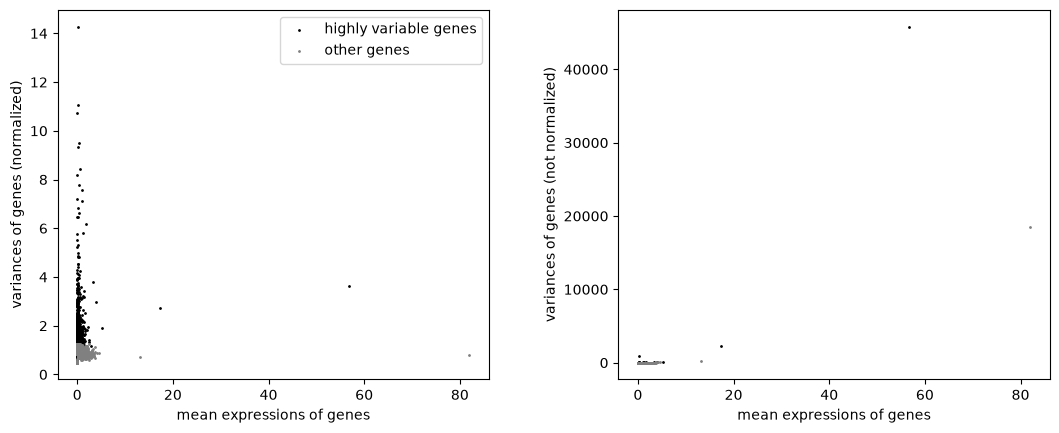

In [ ]:
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000, batch_key="batch", layer="counts")

print("HVGs selected:", adata.var["highly_variable"].sum())
print("HVGs selected:", adata.var["highly_variable"].value_counts())
print(adata.var.loc[adata.var["highly_variable"], "highly_variable_nbatches"].value_counts().sort_index())

sc.pl.highly_variable_genes(adata)

In [ ]:
adata.raw = adata
print("adata.raw set to adata, shape:", adata.raw.shape)

adata.raw set to adata, shape: (163951, 24051)


In [ ]:
adata.raw.shape

(163951, 24051)

In [ ]:
adata = adata[:, adata.var["highly_variable"]].copy()
print("adata filtered to HVGs, shape:", adata.shape)
print("adata.raw shape:", adata.raw.shape)

adata filtered to HVGs, shape: (163951, 2000)
adata.raw shape: (163951, 24051)


In [ ]:
#scaling the HVGs
sc.pp.scale(adata, max_value = 10)
print("After scaling:")
print(".  X max = ", round(float(adata.X.max()), 3))
print(".  X min = ", round(float(adata.X.min()), 3))
print(".  Mean of a few genes:", np.mean(adata.X[:, :5], axis=0))

/usr/lib/python3.12/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


After scaling:
.  X max =  10.0
.  X min =  -3.747
.  Mean of a few genes: [-9.73273367e-04 -5.56491971e-03 -1.01352255e-02 -1.00069823e-02
 -2.11100940e-14]


In [ ]:
sc.tl.pca(adata, n_comps=50, svd_solver="arpack", random_state=config.SEED)
print("PCA done, shape:", adata.obsm["X_pca"].shape)
print("Variance explained by the first 10 PCs:", adata.uns["pca"]["variance_ratio"][:10])

PCA done, shape: (163951, 50)
Variance explained by the first 10 PCs: [0.05225115 0.02860785 0.01496942 0.00905593 0.006257   0.00509215
 0.00467154 0.00407739 0.00339637 0.00333762]


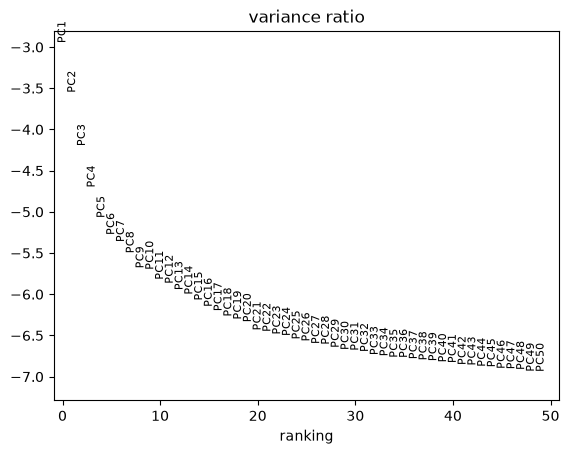

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

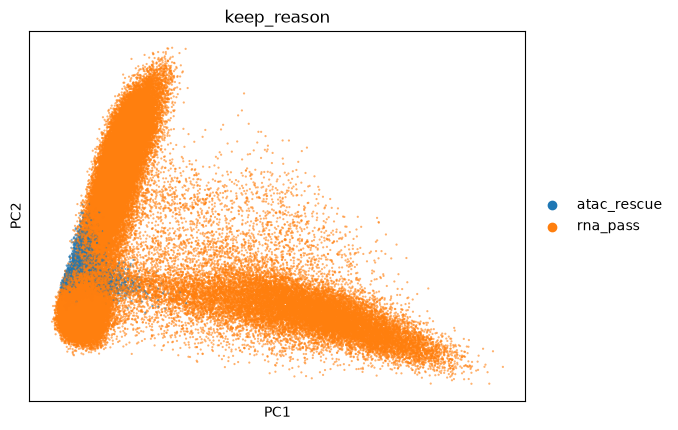

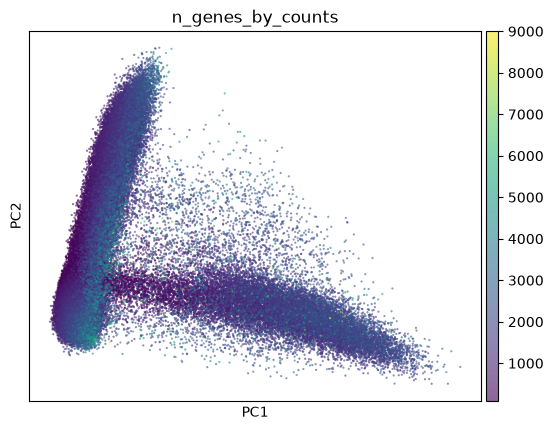

In [ ]:
sc.pl.pca(adata, color="keep_reason", components="1, 2", size=10, alpha=0.6)
sc.pl.pca(adata, color="n_genes_by_counts", components="1, 2", size=10, alpha=0.6)

In [ ]:
adata.uns["stage_03"] = {
    "scanpy": sc.__version__,
    "n_hvg": int(adata.n_vars),
    "n_pcs_computed": 50,
    "n_pcs_chosen": 30,              
    "hvg_flavor": "seurat_v3",
    "hvg_batch_aware": True,
    "normalization": "normalize_total(1e4) + log1p",
    "seed": config.SEED,
}
out = config.CHECKPOINTS / "03_pca.h5ad"
adata.write_h5ad(out, compression="gzip")
print(f"saved {out.name}: {adata.shape[0]:,} cells x {adata.shape[1]:,} HVGs, "
      f"PCA {adata.obsm['X_pca'].shape[1]} comps, full genes in .raw ({adata.raw.shape[1]:,})")

/tmp/ipykernel_1666478/3958088216.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  "scanpy": sc.__version__,


saved 03_pca.h5ad: 163,951 cells x 2,000 HVGs, PCA 50 comps, full genes in .raw (24,051)


In [ ]:
!pip install harmonypy

In [ ]:
print("dtype:", adata.obs["batch"].dtype)
print(adata.obs["batch"].value_counts(dropna=False))
print("n unique:", adata.obs["batch"].nunique())
print("categories (if categorical):",
      adata.obs["batch"].cat.categories.tolist() if hasattr(adata.obs["batch"], "cat") else "not categorical")

dtype: category
batch
1    98251
2    65700
Name: count, dtype: int64
n unique: 2
categories (if categorical): ['1', '2']


In [ ]:
import harmonypy
import numpy as np

ho = harmonypy.run_harmony(
    adata.obsm["X_pca"].astype(np.float64),
    adata.obs,
    vars_use=["batch"],
)

Z = ho.Z_corr                                
print("Z_corr shape:", Z.shape)                
assert Z.shape == adata.obsm["X_pca"].shape, \
    f"shape mismatch: {Z.shape} vs {adata.obsm['X_pca'].shape}"

adata.obsm["X_pca_harmony"] = np.asarray(Z)
print("harmonized embedding stored:", adata.obsm["X_pca_harmony"].shape)

2026-10-23 12:59:14,064 - harmonypy - INFO - Running Harmony
2026-10-23 12:59:14,065 - harmonypy - INFO -   Parameters:
2026-10-23 12:59:14,065 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-23 12:59:14,065 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-23 12:59:14,065 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-23 12:59:14,066 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-23 12:59:14,066 - harmonypy - INFO -     nclust: 100
2026-10-23 12:59:14,066 - harmonypy - INFO -     block_size: 0.05
2026-10-23 12:59:14,066 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-23 12:59:14,067 - harmonypy - INFO -     theta: [2. 2.]
2026-10-23 12:59:14,067 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-23 12:59:14,067 - harmonypy - INFO -     verbose: True
2026-10-23 12:59:14,067 - harmonypy - INFO -     random_state: 0
2026-10-23 12:59:14,067 - harmonypy - INFO -   Data: 50 PCs × 163951 cells
2026-10-23 12:59:14,068 - harmonypy - INFO -   Ba

2026-10-23 12:59:14,111 - harmonypy - INFO - Computing initial centroids...
2026-10-23 12:59:14,231 - harmonypy - INFO - Initialization complete.
2026-10-23 12:59:14,231 - harmonypy - INFO - Iteration 1 of 10
2026-10-23 12:59:14,333 - harmonypy - INFO - Iteration 2 of 10
2026-10-23 12:59:14,431 - harmonypy - INFO - Iteration 3 of 10
2026-10-23 12:59:14,529 - harmonypy - INFO - Iteration 4 of 10
2026-10-23 12:59:14,628 - harmonypy - INFO - Converged after 4 iterations


Z_corr shape: (163951, 50)
harmonized embedding stored: (163951, 50)


In [ ]:
# nwighbors + UMAP on raw PCA
sc.pp.neighbors(adata, n_pcs=config.N_PCS, use_rep="X_pca", key_added="neighbors_raw")
sc.tl.umap(adata, neighbors_key="neighbors_raw")
adata.obsm["X_umap_raw"] = adata.obsm["X_umap"].copy()

#neighbors + UMAP on harmonized PCA
sc.pp.neighbors(adata, n_pcs=config.N_PCS, use_rep="X_pca_harmony", key_added="neighbors_harmony")
sc.tl.umap(adata, neighbors_key="neighbors_harmony")
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()

print("UMAPs computed, stored in .obsm['X_umap_raw'] and .obsm['X_umap_harmony']")

/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


UMAPs computed, stored in .obsm['X_umap_raw'] and .obsm['X_umap_harmony']


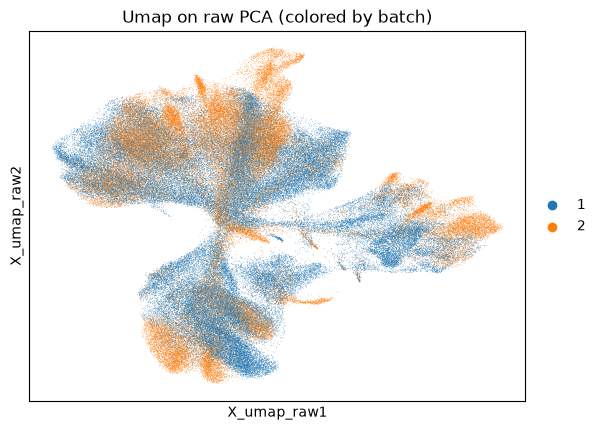

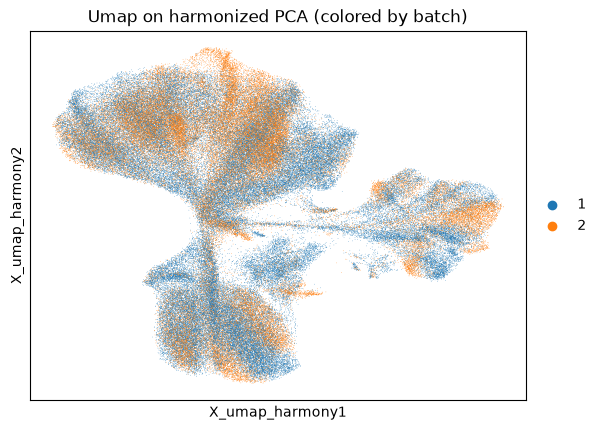

In [ ]:
sc.pl.embedding(adata, "X_umap_raw", color="batch", title="Umap on raw PCA (colored by batch)")
sc.pl.embedding(adata, "X_umap_harmony", color="batch", title="Umap on harmonized PCA (colored by batch)")

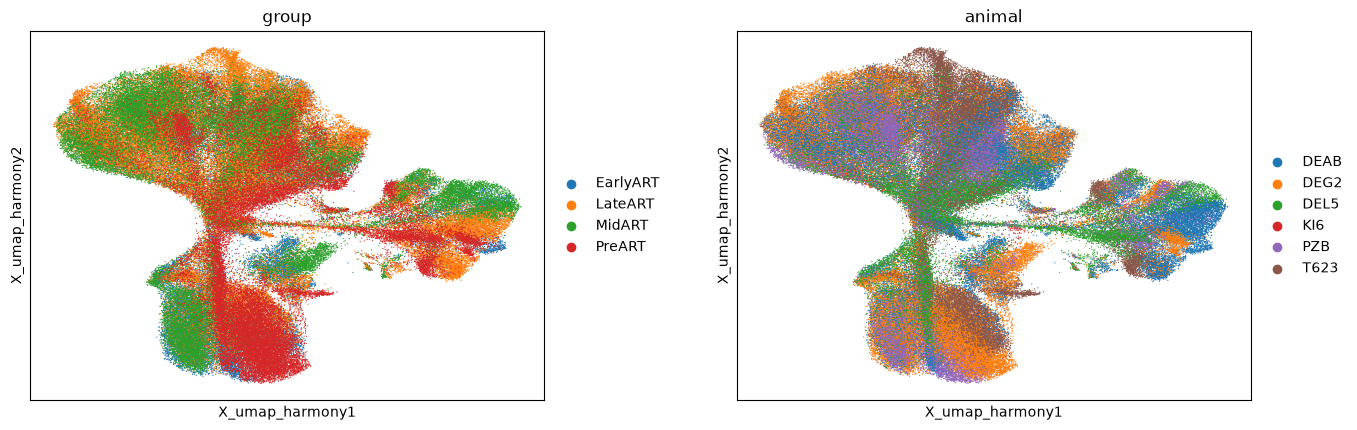

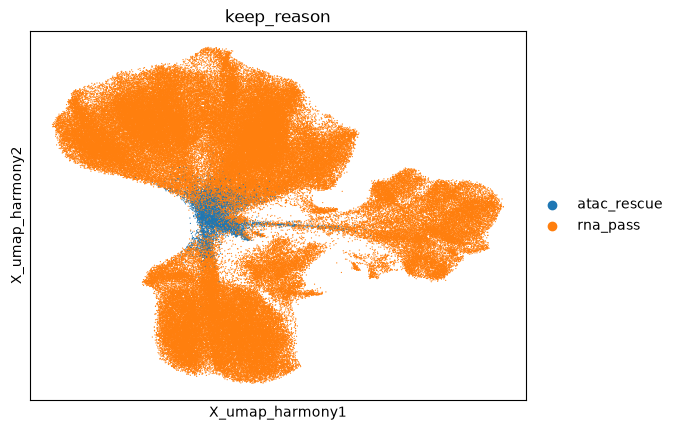

In [ ]:
sc.pl.embedding(adata, "X_umap_harmony", color=["group", "animal"], size=3, ncols=2, wspace=0.25, frameon=True)
sc.pl.embedding(adata, "X_umap_harmony", color="keep_reason", size=3)   

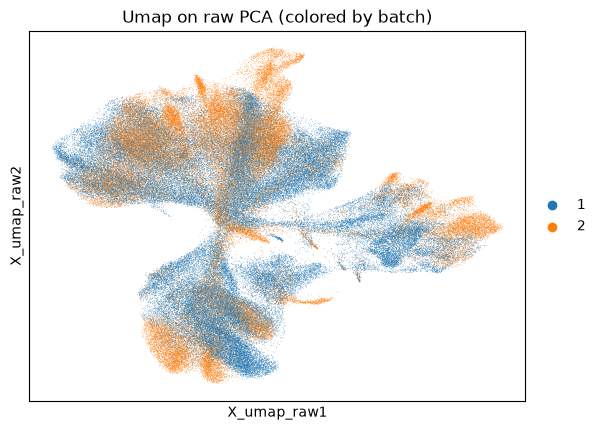

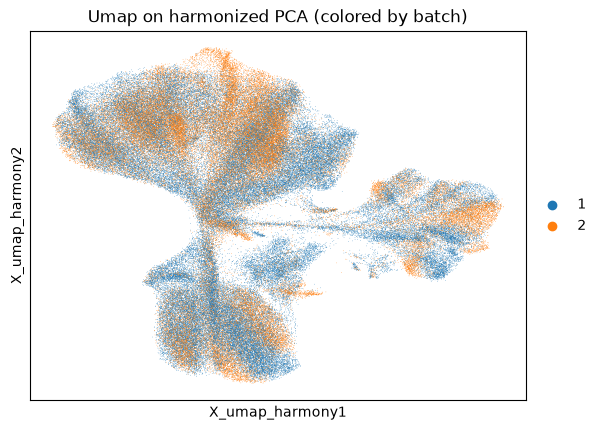

In [ ]:
sc.pl.embedding(adata, "X_umap_raw", color="batch", title="Umap on raw PCA (colored by batch)")
sc.pl.embedding(adata, "X_umap_harmony", color="batch", title="Umap on harmonized PCA (colored by batch)")

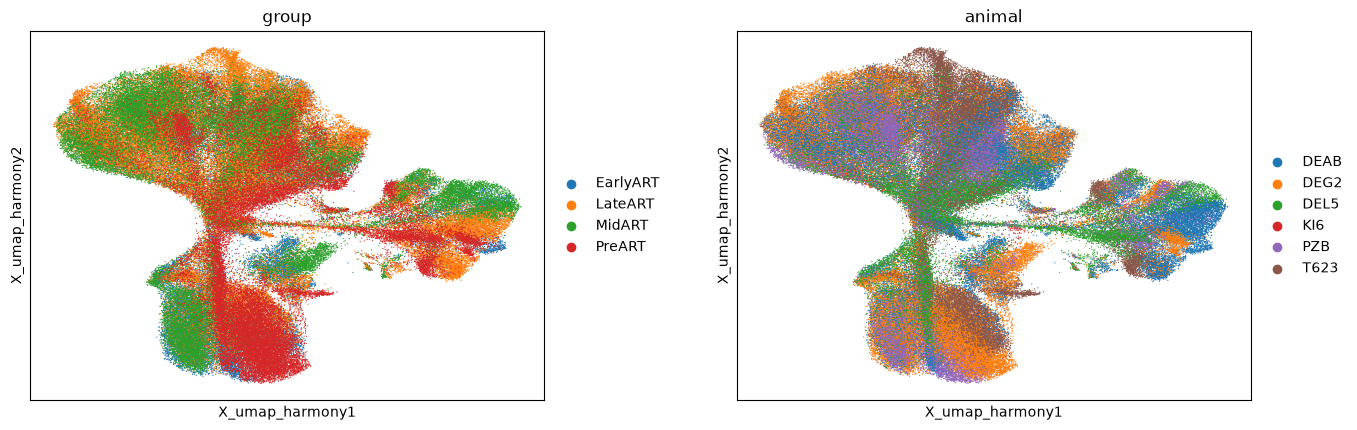

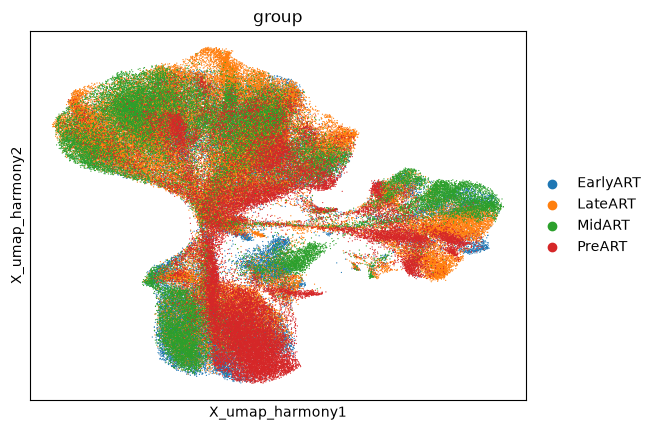

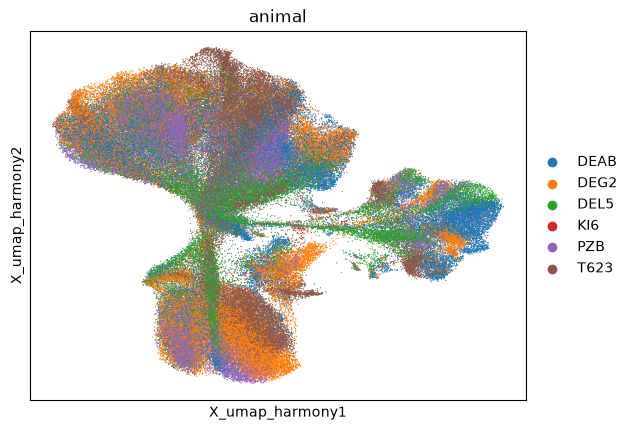

In [ ]:
sc.pl.embedding(adata, "X_umap_harmony", color=["group", "animal"], size=3, ncols=2, wspace=0.25, frameon=True)
sc.pl.embedding(adata, "X_umap_harmony", color="group",  size=3)
sc.pl.embedding(adata, "X_umap_harmony", color="animal", size=3)

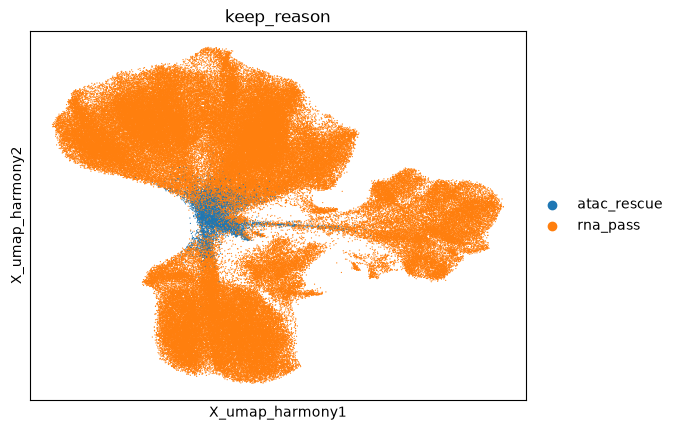

In [ ]:
sc.pl.embedding(adata, "X_umap_harmony", color="keep_reason", size=3)

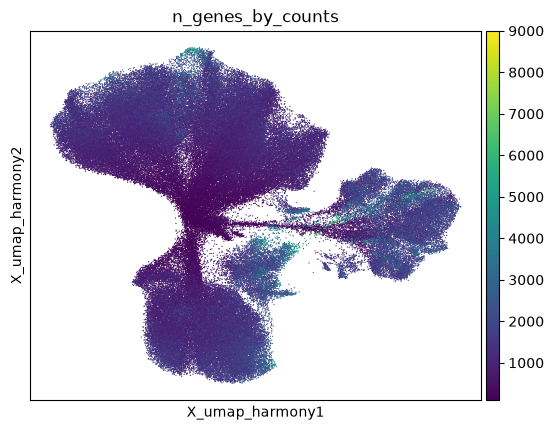

In [ ]:
sc.pl.embedding(adata, "X_umap_harmony", color="n_genes_by_counts", size=3)

In [ ]:
sc.tl.leiden(adata, resolution=1.0, neighbors_key="neighbors_harmony", key_added="leiden",
             random_state=config.SEED, flavor="igraph", n_iterations=2)
print("clusters found:", adata.obs["leiden"].nunique())
print(adata.obs["leiden"].value_counts().sort_index())

clusters found: 22
leiden
0     15311
1     10852
2      5988
3      4428
4      1108
5     15010
6     11736
7      5689
8      7388
9     18219
10     6029
11    11575
12     6101
13    15004
14     7657
15    10453
16     2892
17     3710
18     3355
19      615
20      704
21      127
Name: count, dtype: int64


In [ ]:
!pip instal seaborn

ERROR: unknown command "instal" - maybe you meant "install"


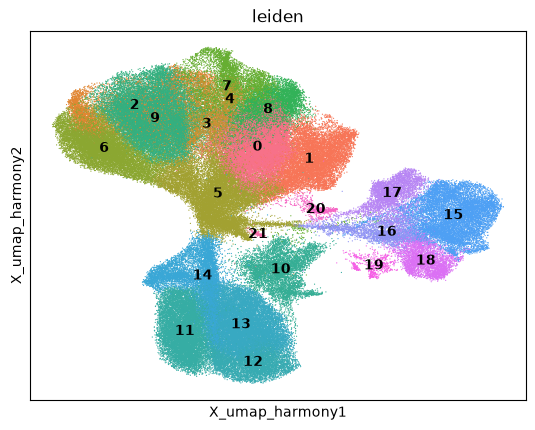

In [ ]:
import seaborn as sns
n = adata.obs["leiden"].nunique()
sc.pl.embedding(adata, "X_umap_harmony", color="leiden", legend_loc="on data", size=3, palette=sns.color_palette("husl", n))

In [ ]:
import pandas as pd
ct = pd.crosstab(adata.obs["leiden"], adata.obs["keep_reason"])
ct["pct_rescue"] = (ct["atac_rescue"] / (ct["atac_rescue"] + ct["rna_pass"]) * 100).round(1)
print(ct.sort_values("pct_rescue", ascending=False))

keep_reason  atac_rescue  rna_pass  pct_rescue
leiden                                        
5                   4625     10385        30.8
14                   520      7137         6.8
21                     8       119         6.3
16                    90      2802         3.1
1                     34     10818         0.3
0                     33     15278         0.2
4                      0      1108         0.0
3                      0      4428         0.0
2                      0      5988         0.0
6                      5     11731         0.0
10                     0      6029         0.0
7                      0      5689         0.0
8                      0      7388         0.0
9                      1     18218         0.0
13                     0     15004         0.0
12                     0      6101         0.0
11                     1     11574         0.0
15                     0     10453         0.0
17                     1      3709         0.0
18           

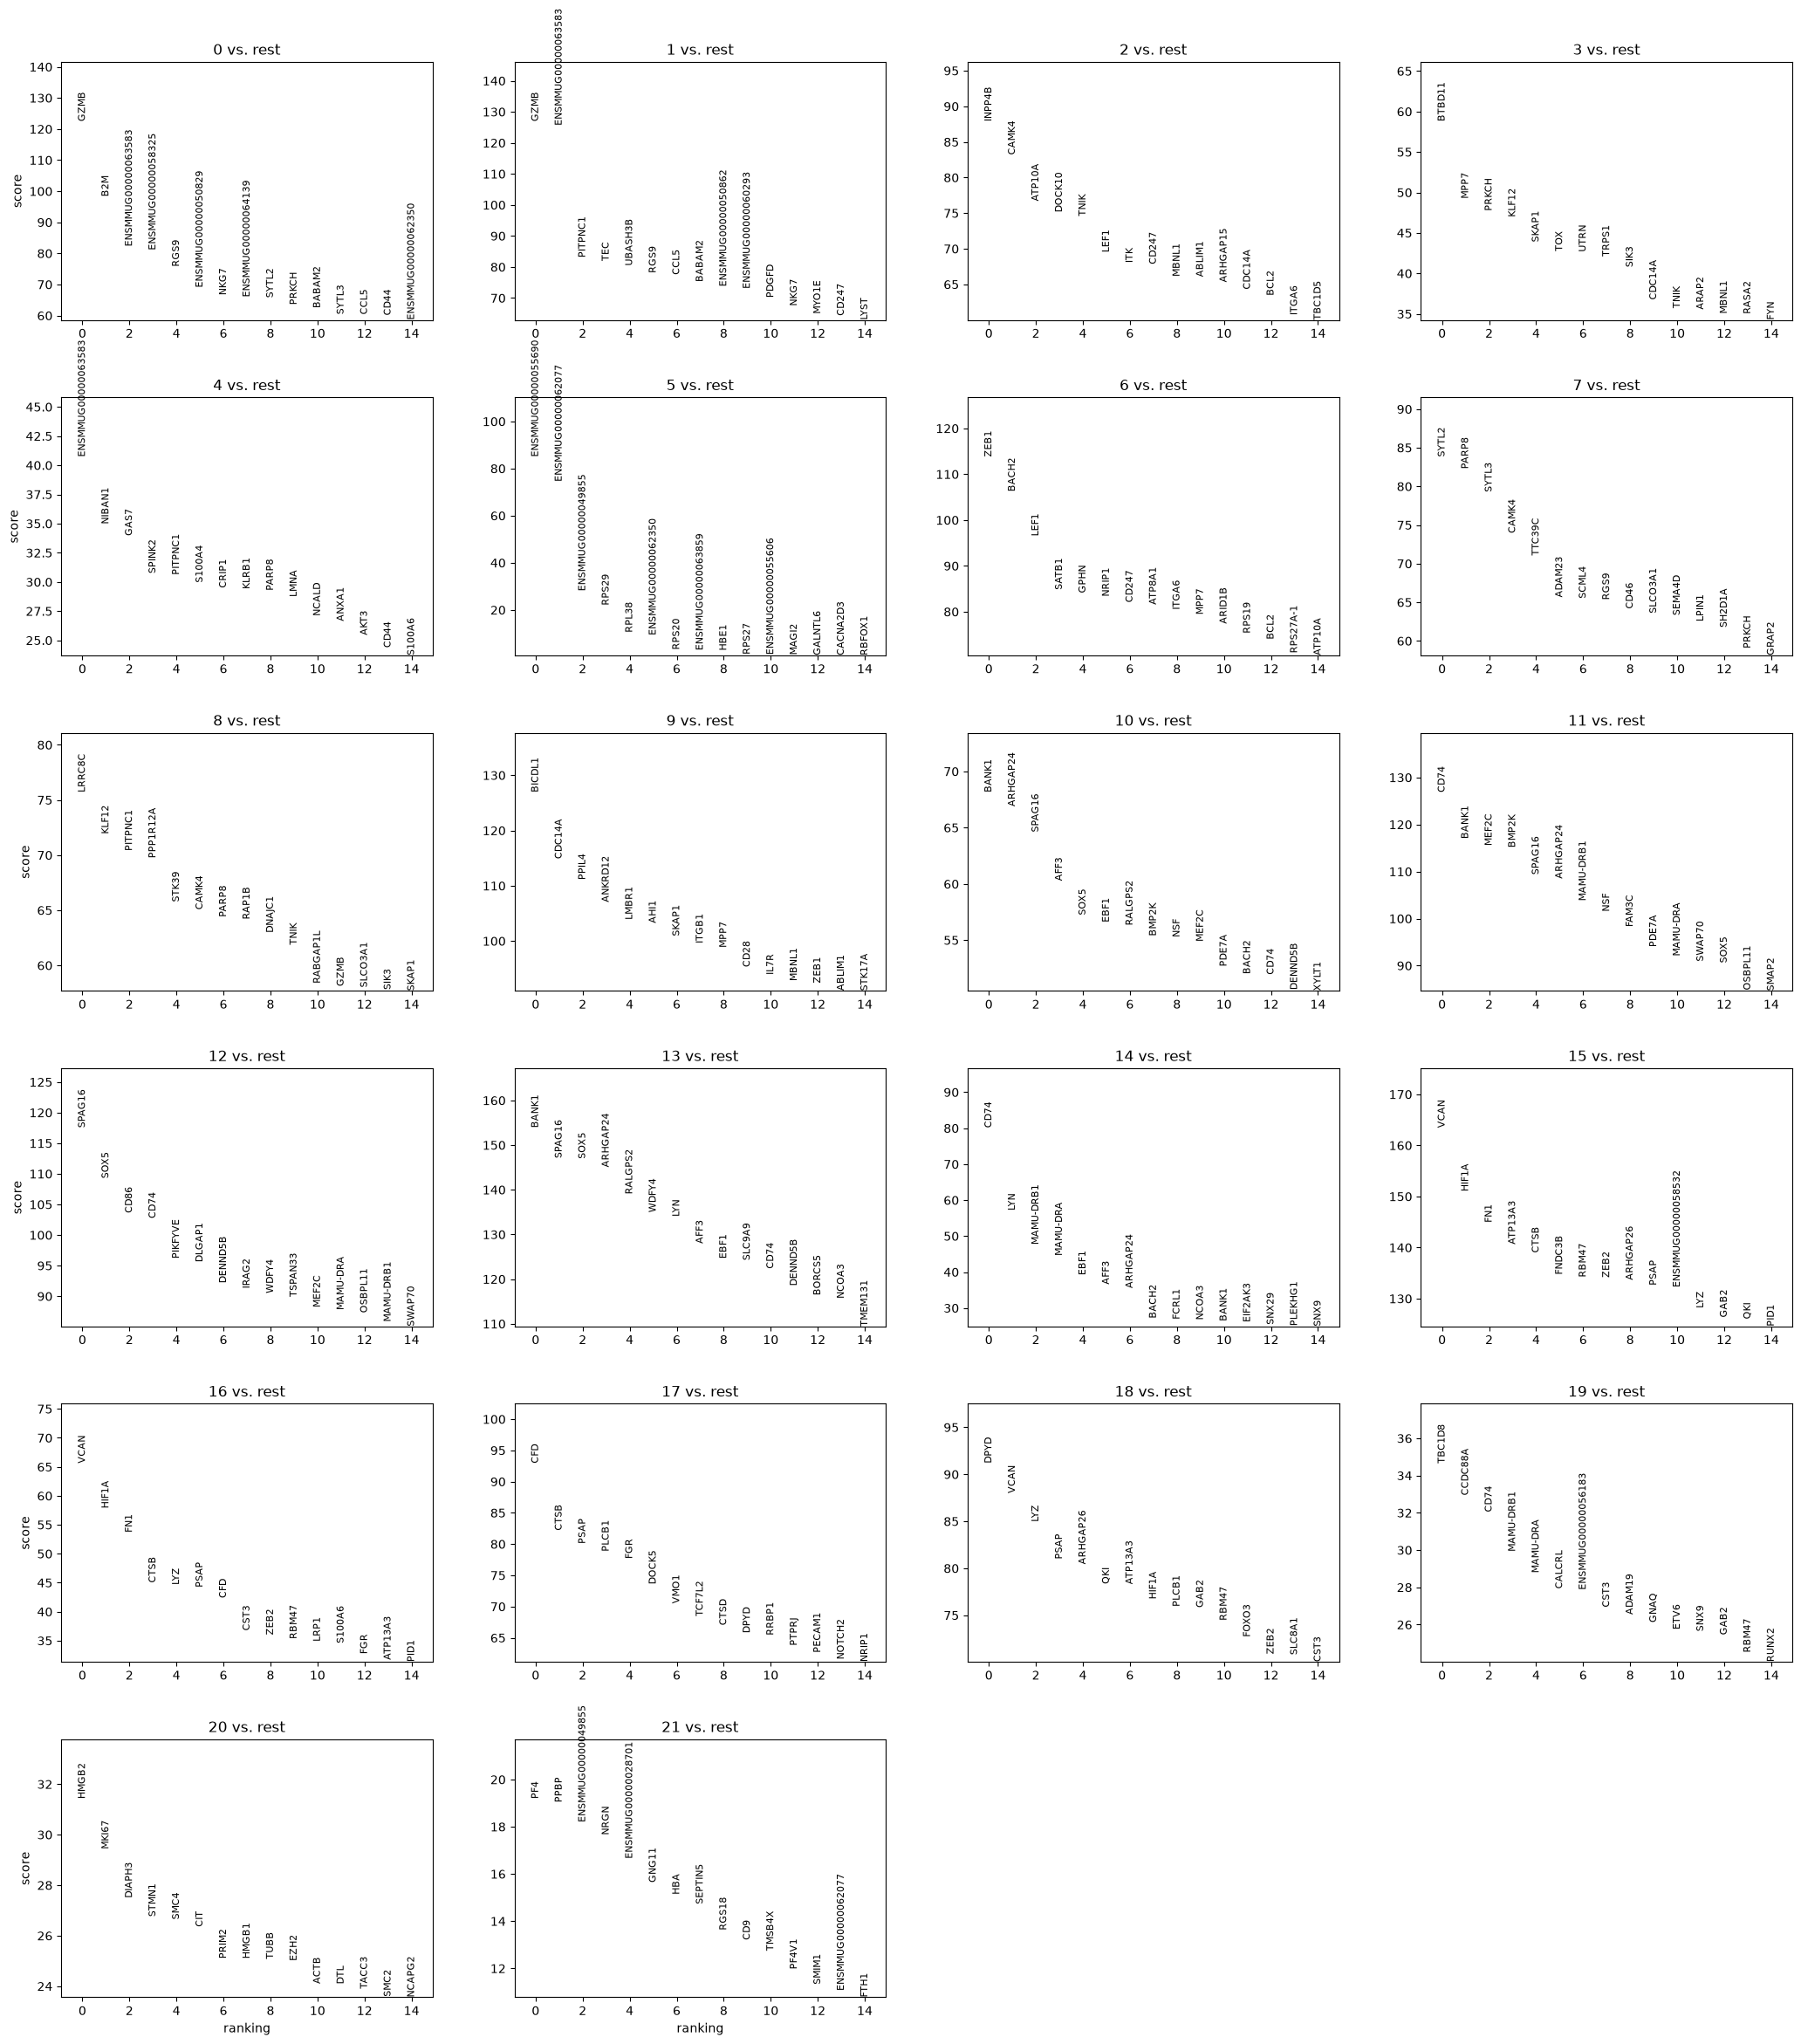

In [ ]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", use_raw=True)
sc.pl.rank_genes_groups(adata, n_genes=15, sharey=False)

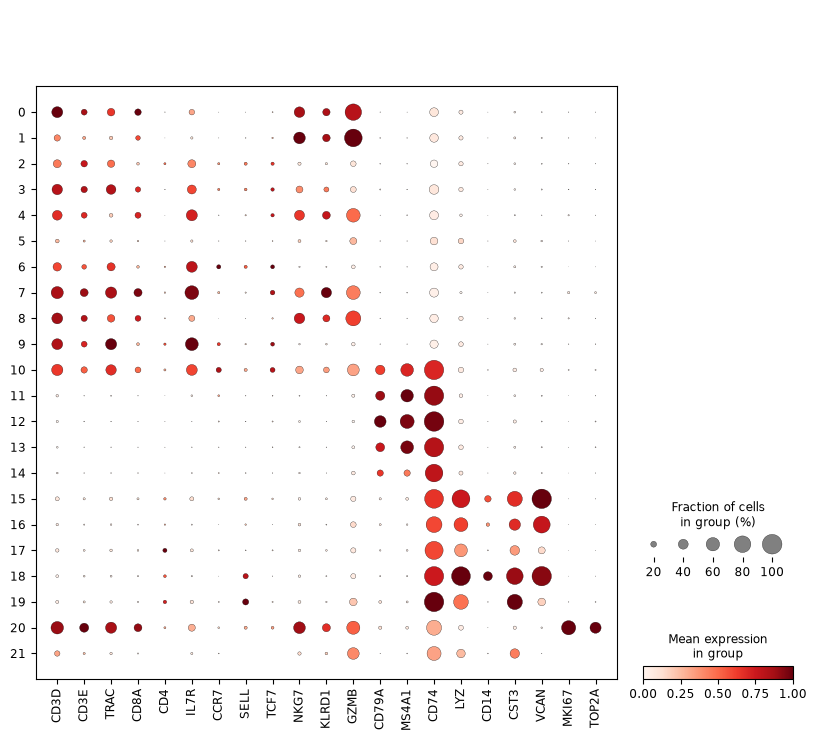

In [ ]:
markers = {
    "T":      ["CD3D","CD3E","TRAC"],
    "CD8":    ["CD8A","CD8B"],
    "CD4/mem":["CD4","IL7R"],
    "rest":   ["CCR7","SELL","TCF7"],
    "NK":     ["NKG7","GNLY","KLRD1","GZMB"],
    "B":      ["CD79A","MS4A1","CD74"],
    "myeloid":["LYZ","CD14","CST3","VCAN"],
    "prolif": ["MKI67","TOP2A"],
}
flat = [g for v in markers.values() for g in v if g in adata.raw.var_names]
sc.pl.dotplot(adata, flat, groupby="leiden", use_raw=True,
              standard_scale="var", dendrogram=False)

In [ ]:
import pandas as pd
res = sc.get.rank_genes_groups_df(adata, group=None)   # already computed earlier
top = (res.sort_values(["group","scores"], ascending=[True,False])
          .groupby("group").head(8))
for cl in sorted(adata.obs["leiden"].unique(), key=int):
    genes = top.loc[top["group"]==cl, "names"].tolist()
    print(f"cluster {cl:>2}: {', '.join(genes)}")

cluster  0: GZMB, B2M, ENSMMUG00000063583, ENSMMUG00000058325, RGS9, ENSMMUG00000050829, NKG7, ENSMMUG00000064139
cluster  1: GZMB, ENSMMUG00000063583, PITPNC1, TEC, UBASH3B, RGS9, CCL5, BABAM2
cluster  2: INPP4B, CAMK4, ATP10A, DOCK10, TNIK, LEF1, ITK, CD247
cluster  3: BTBD11, MPP7, PRKCH, KLF12, SKAP1, TOX, UTRN, TRPS1
cluster  4: ENSMMUG00000063583, NIBAN1, GAS7, SPINK2, PITPNC1, S100A4, CRIP1, KLRB1
cluster  5: ENSMMUG00000055690, ENSMMUG00000062077, ENSMMUG00000049855, RPS29, RPL38, ENSMMUG00000062350, RPS20, ENSMMUG00000063859
cluster  6: ZEB1, BACH2, LEF1, SATB1, GPHN, NRIP1, CD247, ATP8A1
cluster  7: SYTL2, PARP8, SYTL3, CAMK4, TTC39C, ADAM23, SCML4, RGS9
cluster  8: LRRC8C, KLF12, PITPNC1, PPP1R12A, STK39, CAMK4, PARP8, RAP1B
cluster  9: BICDL1, CDC14A, PPIL4, ANKRD12, LMBR1, AHI1, SKAP1, ITGB1
cluster 10: BANK1, ARHGAP24, SPAG16, AFF3, SOX5, EBF1, RALGPS2, BMP2K
cluster 11: CD74, BANK1, MEF2C, BMP2K, SPAG16, ARHGAP24, MAMU-DRB1, NSF
cluster 12: SPAG16, SOX5, CD86, CD74, PIKF

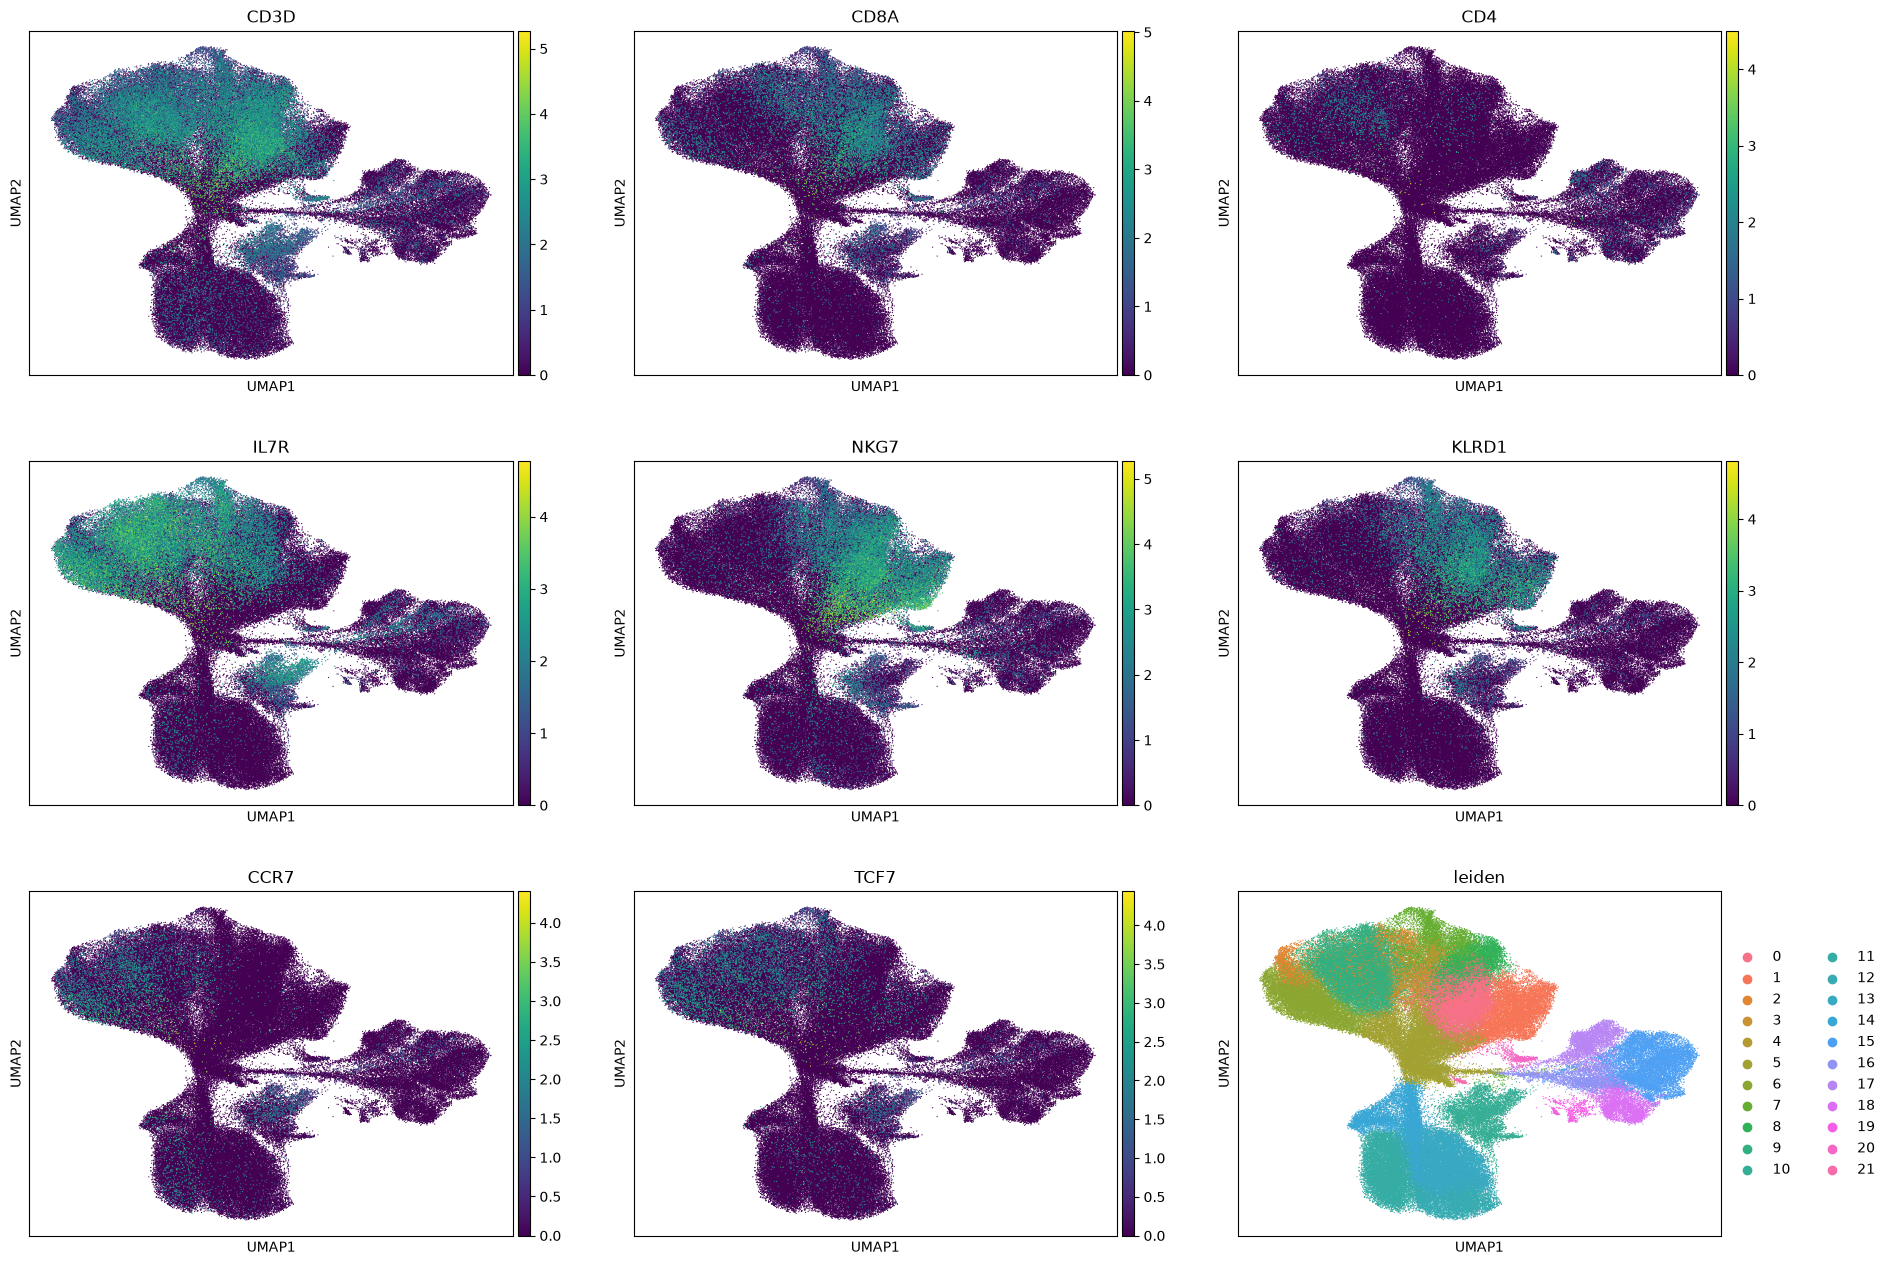

In [ ]:
sc.pl.umap(adata, color=["CD3D","CD8A","CD4","IL7R","NKG7","KLRD1","CCR7","TCF7","leiden"],
           use_raw=True, size=3, ncols=3)

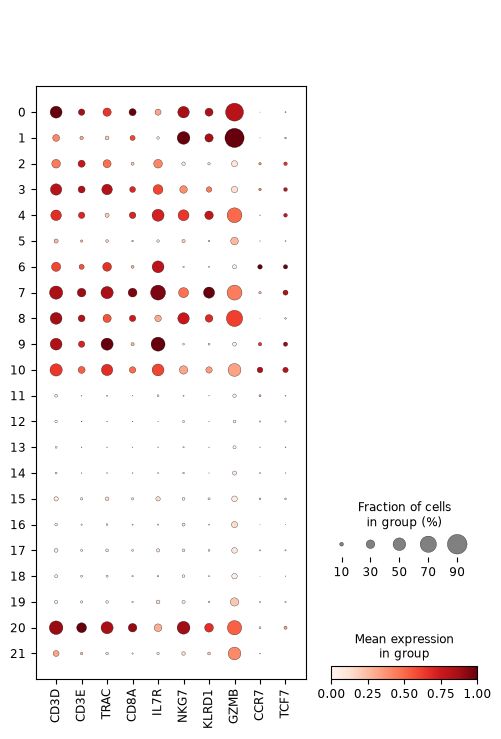

In [ ]:
sc.pl.dotplot(adata, ["CD3D","CD3E","TRAC","CD8A","IL7R","NKG7","KLRD1","GZMB","CCR7","TCF7"],
              groupby="leiden", use_raw=True, standard_scale="var")

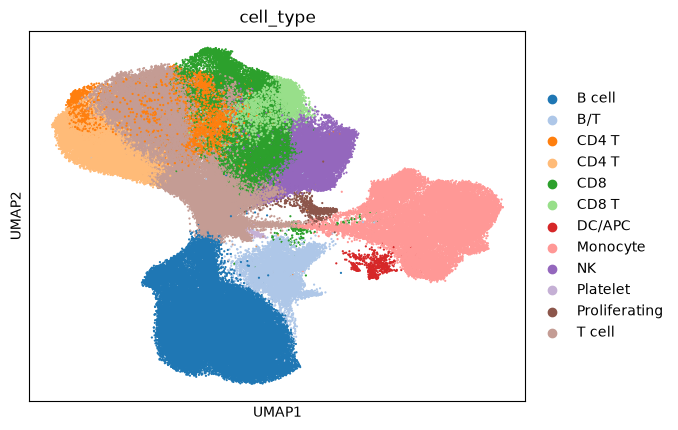

In [ ]:
cluster_labels = {
    "0":"CD8", "1":"NK", "2":"CD4 T", "3":"CD4 T",
    "4":"T cell", "5":"T cell",
    "6":"CD4 T ", "7":"CD8", "8":"CD8 T",
    "9":"T cell", "10":"B/T ",
    "11":"B cell","12":"B cell","13":"B cell","14":"B cell",
    "15":"Monocyte","16":"Monocyte","17":"Monocyte","18":"Monocyte",
    "19":"DC/APC","20":"Proliferating","21":"Platelet",
}
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_labels).astype("category")
sc.pl.umap(adata, color="cell_type", legend_loc="right margin", size=10, palette=sns.color_palette("tab20", n_colors=len(cluster_labels)))